# Exercise 1

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

# Functions
square_wave = lambda x: 1 if x <= np.pi else -1
sawtooth_wave = lambda x: x/np.pi if x <= np.pi else x/np.pi - 2

# Fourier coefficient calculation
def ak(k, f):
    coef = 1/np.pi
    func = lambda x: f(x) * np.sin(k*x)
    alpha_k = coef * quad(func, 0, 2*np.pi)[0]
    return alpha_k # apply the scipy's quad function for calculating the integral

# Number of Fourier coefficients to compute
N = 7

# Compute Fourier coefficients for square wave
print("Square wave Fourier coefficients:")
for k in range(0, N+1):
    coefficient = ak(k, square_wave)
    print(f"a{k} = {coefficient}")

# Compute Fourier coefficients for sawtooth wave  
print("\nSawtooth wave Fourier coefficients:")
for k in range(0, N+1):
    coefficient = ak(k, sawtooth_wave)
    print(f"a{k} = {coefficient}")

Square wave Fourier coefficients:
a0 = 0.0
a1 = 1.2732395447351628
a2 = 3.754541264851309e-17
a3 = 0.42441318157838775
a4 = -1.2393328763590725e-17
a5 = 0.2546479089470325
a6 = 2.0367486654578007e-16
a7 = 0.18189136353359475

Sawtooth wave Fourier coefficients:
a0 = 0.0
a1 = 0.6366197723675814
a2 = -0.31830988618379064
a3 = 0.21220659078919388
a4 = -0.15915494309189526
a5 = 0.1273239544735162
a6 = -0.10610329539459704
a7 = 0.0909456817667973


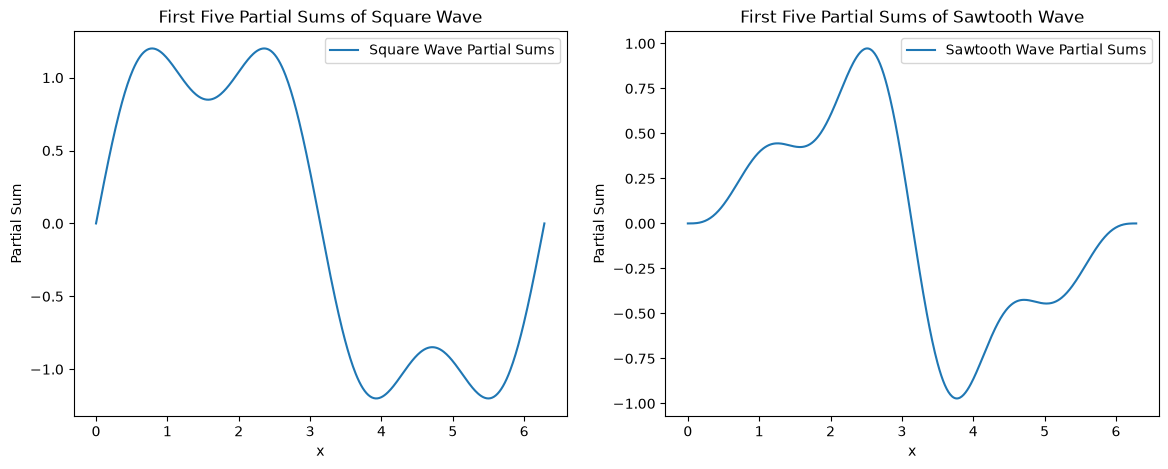

In [2]:
N = 5
k_values = np.arange(0, N)
x = np.linspace(0, 2*np.pi, 500)

# Calculate partial sums
def partial_sum(coefficient, k, x):
    partial_sums = np.zeros_like(x)
    for k_value, coeff in zip(k, coefficient):
        partial_sums += coeff*np.sin(k_value*x)
    return partial_sums

# Computing coefficinets in array for np.arange() k values
def compute_fourier_coefficients(func, k_values):
    # We will compute the integral using scipy's quad function
    coefficients = np.array([quad(lambda x: func(x) * np.sin(k * x), 0, 2 * np.pi)[0] for k in k_values])
    return coefficients / np.pi

square_sum = partial_sum(compute_fourier_coefficients(square_wave,k_values), k_values, x) 
sawtooth_sum = partial_sum(compute_fourier_coefficients(sawtooth_wave,k_values), k_values, x)


# Plot the first five partial sums for the square wave
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(x, square_sum, label='Square Wave Partial Sums')
plt.title('First Five Partial Sums of Square Wave')
plt.xlabel('x')
plt.ylabel('Partial Sum')
plt.legend()

# Plot the first five partial sums for the sawtooth wave
plt.subplot(1, 2, 2)
plt.plot(x, sawtooth_sum, label='Sawtooth Wave Partial Sums')
plt.title('First Five Partial Sums of Sawtooth Wave')
plt.xlabel('x')
plt.ylabel('Partial Sum')
plt.legend()
plt.show()

# Exercise 2

$F_k = \sum_{n=0}^{N-1} f_n e^{-i \left(2\pi \frac{k}{N}\right) n}$

for $k = 0$ to $N-1$, where $N=4$, the DFT are $F_0$ to $F_3$

In [3]:
def DFT(f):
    N = len(f)
    n = np.arange(0, N)
    k = n.reshape((N,1)) # convert to vector
    A = np.exp(-2j * np.pi * k/N * n)
    F = A@f
    return F

v = 4
f = np.random.randn(v, 1)
F = DFT(f)
print(F)

[[1.39570608+0.00000000e+00j]
 [1.26835406-9.70551948e-01j]
 [2.79999294+3.92417768e-16j]
 [1.26835406+9.70551948e-01j]]


# Exercise 3

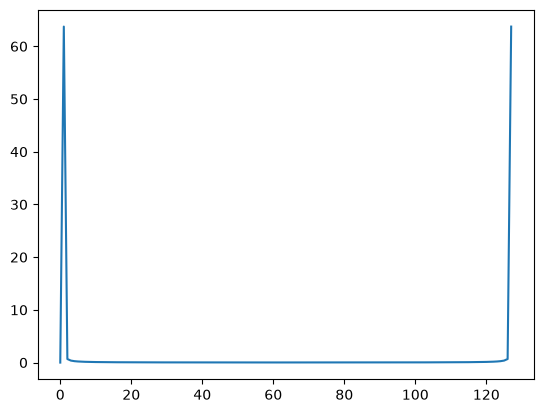

In [4]:
x = np.linspace(0, 2*np.pi, 128)

f = np.sin(x)
F = DFT(f)
plt.plot(np.abs(F))

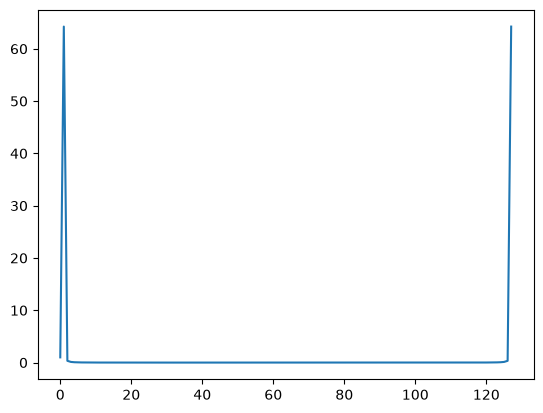

In [5]:
f = np.cos(x)
F = DFT(f)
plt.plot(np.abs(F))

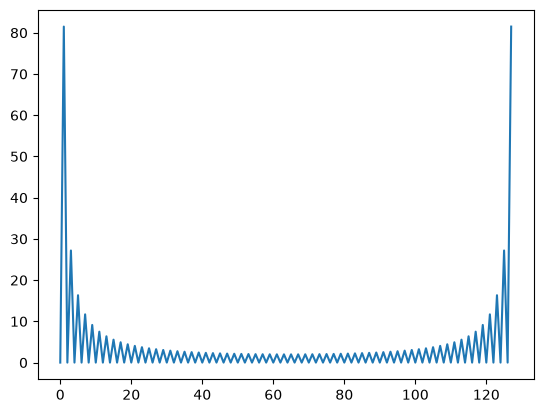

In [6]:
f = np.array([1 if xk < np.pi else -1 for xk in x])
F = DFT(f)
plt.plot(np.abs(F))

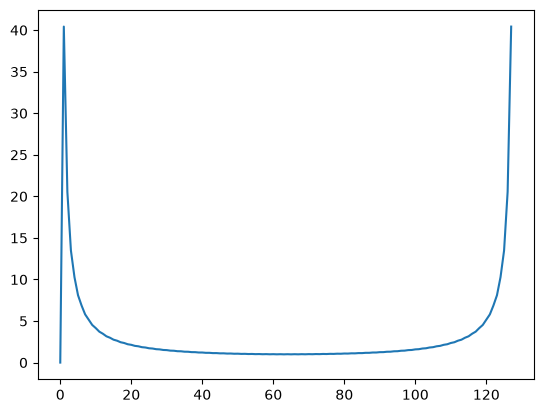

In [7]:
f = np.array([xk/np.pi if xk < np.pi else xk/np.pi - 2 for xk in x])  
F = DFT(f)
plt.plot(np.abs(F))

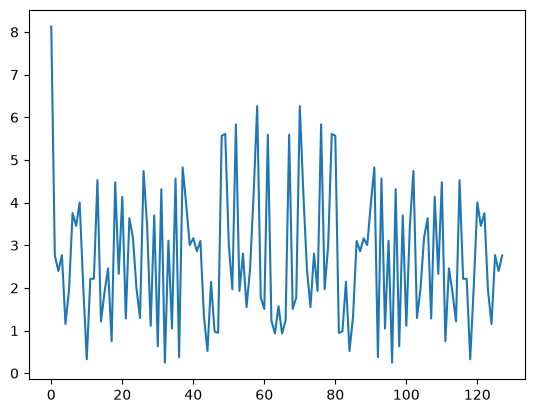

In [8]:
f = np.random.default_rng(2024).uniform(size=128) - 0.5
F = DFT(f)  
plt.plot(np.abs(F))